<a href="https://colab.research.google.com/github/masoumeh157ch/C-Minus-Compiler/blob/main/phase1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import re
from google.colab import files
import shutil

print("Please upload your file:")
uploaded_content = files.upload()
input_name = list(uploaded_content.keys())[0]
shutil.move(input_name, "input.txt")


Please upload your file:


Saving TE5.txt to TE5.txt


'input.txt'

In [ ]:
kw_set = {'if',
          'else',
          'void',
          'int',
          'repeat',
          'break',
          'until',
          'return'}
kw_tags = {
    'if': 'KEYWORD',
    'else': 'KEYWORD',
    'void': 'KEYWORD',
    'int': 'KEYWORD',
    'repeat': 'KEYWORD',
    'break': 'KEYWORD',
    'until': 'KEYWORD',
    'return': 'KEYWORD',
    ';': 'SYMBOL', ',':
    'SYMBOL',
    '(': 'SYMBOL',
    ')': 'SYMBOL',
    '{': 'SYMBOL',
    '}': 'SYMBOL',
    '[': 'SYMBOL',
    ']': 'SYMBOL',
    '+': 'SYMBOL',
    '-': 'SYMBOL',
    '*': 'SYMBOL',
    '/': 'SYMBOL',
    '=': 'SYMBOL',
    '<': 'SYMBOL',
    '==': 'SYMBOL'
}
sym_list = sorted(['==', ';', ',', '(', ')', '{', '}', '[', ']', '+', '-', '*', '/', '=', '<'], key=lambda s: -len(s))


In [ ]:
import sys
from pathlib import Path

module_to_clear = "CminusLexer"
custom_path = "/content/antlr_gen"

if module_to_clear in sys.modules:
    sys.modules.pop(module_to_clear)

sys.path = [str(Path(custom_path))] + sys.path


In [ ]:
def replace_with_spaces(match):
    return ' ' * len(match.group())

with open("input.txt", "r") as reader:
    raw_code = reader.read()

raw_code = re.sub(r'/\*.*?\*/', replace_with_spaces, raw_code, flags=re.DOTALL)
raw_code = re.sub(r'//.*', replace_with_spaces, raw_code)


In [ ]:
log = []
for match in re.finditer(r'\*/', raw_code):
    row = raw_code[:match.start()].count('\n') + 1
    log.append((row, '*/', 'Unmatched comment'))

left_open = re.search(r'/\*.*$', raw_code, flags=re.DOTALL)
if left_open:
    row = raw_code[:left_open.start()].count('\n') + 1
    snippet = left_open.group(0)[:10].replace('\n', ' ')
    log.append((row, snippet + '...', 'Unclosed comment'))
    raw_code = raw_code.replace(left_open.group(0), ' ' * len(left_open.group(0)))

raw_code = re.sub(r'(\d+)([a-zA-Z_])', r'\1 \2', raw_code)


In [ ]:
all_tokens = []
symbol_log = {k: 0 for k in kw_set}
lines_seq = raw_code.splitlines()

for lno, txt in enumerate(lines_seq, start=1):
    p = 0
    while p < len(txt):
        seg = txt[p:]

        if re.match(r'^[ \t\r\f\v]', seg):
            p += 1
            continue

        digit = re.match(r'^\d+', seg)
        if digit:
            val = digit.group()
            all_tokens.append((lno, 'NUM', val))
            p += len(val)
            continue

        idf = re.match(r'^[A-Za-z_][A-Za-z0-9_]*', seg)
        if idf:
            val = idf.group()
            tag = 'KEYWORD' if val in kw_set else 'ID'
            all_tokens.append((lno, tag, val))
            if tag == 'ID' and val not in symbol_log:
                symbol_log[val] = lno
            p += len(val)
            continue

        is_found = False
        for symb in sym_list:
            if seg.startswith(symb):
                all_tokens.append((lno, 'SYMBOL', symb))
                p += len(symb)
                is_found = True
                break
        if is_found:
            continue

        log.append((lno, seg[0], 'Invalid input'))
        p += 1


In [ ]:
with open("tokens.txt", "w") as out_tok:
    curr_ln = -1
    for lno, typ, txt in all_tokens:
        if lno != curr_ln:
            if curr_ln != -1:
                out_tok.write("\n")
            out_tok.write(f"{lno}.\t")
            curr_ln = lno
        out_tok.write(f"({typ}, {txt}) ")


In [ ]:
with open("lexical_errors.txt", "w") as out_err:
    if not log:
        out_err.write("There is no lexical error.")
    else:
        curr_ln = -1
        for lno, val, desc in log:
            if lno != curr_ln:
                if curr_ln != -1:
                    out_err.write("\n")
                out_err.write(f"{lno}.\t")
                curr_ln = lno
            out_err.write(f"({val}, {desc}) ")


In [ ]:
with open("symbol_table.txt", "w") as out_sym:
    for idx, key in enumerate(sorted(symbol_log.keys()), start=1):
        out_sym.write(f"{idx}.\t{key}\n")


In [ ]:
!pip install graphviz


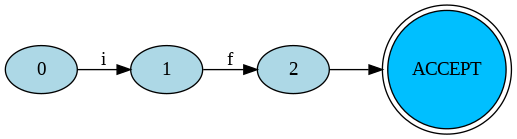

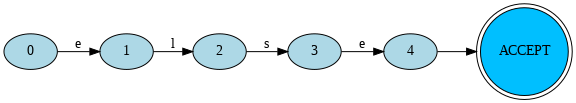

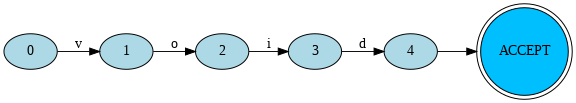

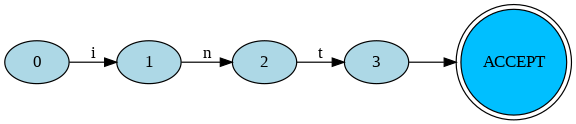

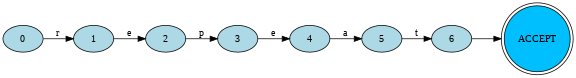

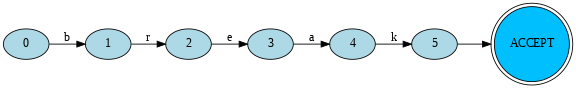

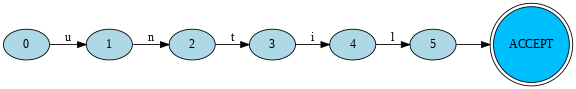

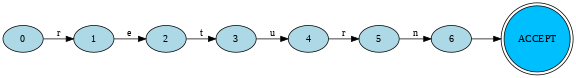

In [ ]:

from graphviz import Digraph
from IPython.display import Image, display

def draw_keyword_dfa(keyword: str, save_path: str):
    g = Digraph(name=f"DFA_{keyword}", format="png")
    g.attr(rankdir='LR', size='6,3')

    prev_state = "0"
    g.node(prev_state, style="filled", fillcolor="lightblue")

    for i, char in enumerate(keyword, start=1):
        curr_state = str(i)
        g.node(curr_state, style="filled", fillcolor="lightblue")
        g.edge(prev_state, curr_state, label=char)
        prev_state = curr_state

    g.node("ACCEPT", style="filled", fillcolor="deepskyblue", shape="doublecircle")
    g.edge(prev_state, "ACCEPT", label=" ")

    g.render(save_path, cleanup=False)
    return save_path + ".png"

# لیست کلیدواژه‌های زبان Cminus
all_keywords = ["if", "else", "void", "int", "repeat", "break", "until", "return"]

# تولید و نمایش DFA برای هر کلیدواژه
for kw in all_keywords:
    path = f"/mnt/data/dfa_{kw}"
    img_file = draw_keyword_dfa(kw, path)
    display(Image(filename=img_file))


In [ ]:
!pip install antlr4-python3-runtime==4.9.3 --force-reinstall


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.0/117.0 kB 2.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for antlr4-python3-runtime: filename=antlr4_python3_runtime-4.9.3-py3-none-any.whl size=144554 sha256=d4279111cd8018661b483712be81cc14610ad7171c3bfea7cdfbe4a31ab13d2f
  Stored in directory: /root/.cache/pip/wheels/1a/97/32/461f837398029ad76911109f07047fde1d7b661a147c7c56d1
Successfully built antlr4-python3-runtime
  Attempting uninstall: antlr4-python3-runtime
    Found existing installation: antlr4-python3-runtime 4.9.3
    Uninstalling antlr4-python3-runtime-4.9.3:
      Successfully uninstalled antlr4-python3-runtime-4.9.3


In [ ]:
!java -version


openjdk version "11.0.27" 2025-04-15
OpenJDK Runtime Environment (build 11.0.27+6-post-Ubuntu-0ubuntu122.04)
OpenJDK 64-Bit Server VM (build 11.0.27+6-post-Ubuntu-0ubuntu122.04, mixed mode, sharing)


In [ ]:
with open("CminusLexer.g4", "w") as f:
    f.write(
"""
lexer grammar CminusLexer;

KEYWORD
    : 'if'
    | 'else'
    | 'void'
    | 'int'
    | 'repeat'
    | 'break'
    | 'until'
    | 'return'
    ;

NUM : [0-9]+ ;

ID  : [a-zA-Z][a-zA-Z0-9]* ;

SYMBOL
    : '=='
    | ';' | ',' | '(' | ')' | '{' | '}' | '[' | ']'
    | '+' | '-' | '*' | '/' | '=' | '<'
    ;

WS              : [ \\t\\r\\n\\f]+ -> skip ;
LINE_COMMENT    : '//' ~[\\r\\n]* -> skip ;
BLOCK_COMMENT   : '/*' .*? '*/' -> skip ;
"""
)

In [ ]:
!wget -O antlr.jar https://www.antlr.org/download/antlr-4.13.1-complete.jar
!pip install antlr4-python3-runtime
!java -jar antlr.jar -Dlanguage=Python3 CminusLexer.g4


--2025-05-21 17:12:45--  https://www.antlr.org/download/antlr-4.13.1-complete.jar
Resolving www.antlr.org (www.antlr.org)... 185.199.108.153, 185.199.109.153, 185.199.110.153, ...
Connecting to www.antlr.org (www.antlr.org)|185.199.108.153|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2139203 (2.0M) [application/java-archive]
Saving to: ‘antlr.jar’

antlr.jar           100%[===================>]   2.04M  --.-KB/s    in 0.08s   

2025-05-21 17:12:45 (25.5 MB/s) - ‘antlr.jar’ saved [2139203/2139203]



In [ ]:
!java -jar antlr.jar -Dlanguage=Python3 CminusLexer.g4
!ls -l CminusLexer*



-rw-r--r-- 1 root root  439 May 21 17:12 CminusLexer.g4
-rw-r--r-- 1 root root 3580 May 21 17:12 CminusLexer.interp
-rw-r--r-- 1 root root 3875 May 21 17:12 CminusLexer.py
-rw-r--r-- 1 root root   66 May 21 17:12 CminusLexer.tokens


In [ ]:
from antlr4 import *
from CminusLexer import CminusLexer
def execute_token_stream():
    with open("input.txt", "r") as src:
        data = src.read()

    lexer_instance = CminusLexer(InputStream(data))
    buffer = CommonTokenStream(lexer_instance)
    buffer.fill()

    with open("1p_ANTLR.txt", "w") as output:
        ln = -1
        for tok in buffer.tokens:
            if tok.type == Token.EOF:
                break
            ln_id = tok.line
            val = tok.text
            category = lexer_instance.symbolicNames[tok.type]
            if ln_id != ln:
                if ln != -1:
                    output.write("\n")
                output.write(f"{ln_id}.\t")
                ln = ln_id
            output.write(f"({category}, {val}) ")
execute_token_stream()



In [ ]:
import re
def retrieve_tokens(filepath):
    result = []
    with open(filepath) as file:
        for row in file:
            parts = row.strip().split('\t')
            if len(parts) != 2:
                continue
            items = re.findall(r'\([A-Z]+, [^)]+\)', parts[1])
            result.extend(items)
    return result


In [ ]:
def compare_token_outputs(verbose=True):
    yours = retrieve_tokens("tokens.txt")
    antlr = retrieve_tokens("1p_ANTLR.txt")

    L = min(len(yours), len(antlr))
    correct = 0
    diff = []

    for idx in range(L):
        if yours[idx] == antlr[idx]:
            correct += 1
        else:
            diff.append((idx, yours[idx], antlr[idx]))


    if verbose:
        print(f"\nMatched: {correct} out of {L}")
        print(f"Mismatches: {len(diff)}\n")
        if diff:
            print("Details of mismatches:")
            for i, a, b in diff:
                print(f"[{i}] yours: {a} | antlr: {b}")


In [ ]:
compare_token_outputs()



Matched: 57 out of 57
Mismatches: 0

